# Power System Load Type Prediction using Machine Learning

**AI / ML Engineering Internship Selection Project**  
**Repository:** `power-load-type-prediction`  
**Dataset:** Industry Power Consumption Time-Series (`load_data.csv`)

## 1. Problem Statement

Electrical power distribution and grid management require precise, proactive categorization of operational load states (`Light_Load`, `Medium_Load`, and `Maximum_Load`). In commercial and industrial facilities, electricity demand varies cyclically throughout the day, across days of the week, and through seasons. Unexpected peak load demands can cause transmission line stress, transformer overload, grid instability, and substantial financial surcharges under peak-demand tariff schemes.

Predicting load types in advance empowers smart grid operators and industrial energy managers to:
1. **Optimize Energy Dispatch & Demand-Side Management (DSM):** Shift flexible power loads from peak to off-peak periods.
2. **Prevent Infrastructure Overload:** Protect substation transformers and capacitors from thermal overheating.
3. **Minimize Carbon Footprint & Costs:** Avoid penalty tariffs and optimize reactive power compensation.

## 2. Objective

The primary objective of this project is to develop, validate, and evaluate an end-to-end, production-grade Machine Learning classification system capable of accurately predicting the **`Load_Type`** of an industrial power system based on continuous operational telemetry and temporal context.

**Core Technical Goals:**
- Perform strict data quality analysis and missing value imputation without data leakage.
- Conduct in-depth Exploratory Data Analysis (EDA) of power telemetry and diurnal load patterns.
- Engineer time-dependent, cyclic, and power-domain interaction features.
- Enforce strict **time-based train/test splitting** reserving the **unseen final month (December 2018)** exclusively for testing.
- Conduct cross-validation strictly on training data using **`TimeSeriesSplit`**.
- Benchmark multiple algorithms (*Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, XGBoost*).
- Perform hyperparameter tuning on top-performing candidates.
- Deliver comprehensive evaluation: Accuracy, Weighted/Macro Precision, Recall, F1-Score, Confusion Matrix, Feature Importance, and Error Analysis.
- Provide a production-ready prediction inference interface and test suite.

## 3. Dataset Description

The dataset comprises 15-minute interval smart meter recordings spanning calendar year 2018 (35,041 records across 12 months).

| Feature Name | Type | Unit / Range | Description |
| :--- | :--- | :--- | :--- |
| **`Date_Time`** | Datetime | DD-MM-YYYY HH:MM | 15-minute interval timestamp |
| **`Usage_kWh`** | Continuous | kWh | Industrial active energy consumed in 15-minute window |
| **`Lagging_Current_Reactive.Power_kVarh`** | Continuous | kVarh | Reactive energy consumed under lagging power factor (inductive loads) |
| **`Leading_Current_Reactive_Power_kVarh`** | Continuous | kVarh | Reactive energy consumed under leading power factor (capacitive loads) |
| **`CO2(tCO2)`** | Continuous | Metric Tons | CO₂ emissions associated with power generation |
| **`Lagging_Current_Power_Factor`** | Continuous | % (0 - 100) | Power factor efficiency during lagging current conditions |
| **`Leading_Current_Power_Factor`** | Continuous | % (0 - 100) | Power factor efficiency during leading current conditions |
| **`NSM`** | Continuous | Seconds | Number of Seconds from Midnight (0 - 86,400) |
| **`Load_Type`** *(Target)* | Categorical | 3 Classes | Operational load regime: `Light_Load`, `Medium_Load`, `Maximum_Load` |

## 4. Import Libraries

In [1]:
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Add project root to Python module path
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

from src.data_loader import load_data, get_dataset_quality_report
from src.eda import (
    plot_target_distribution,
    plot_missing_values,
    plot_numerical_distributions,
    plot_correlation_heatmap,
    plot_usage_over_time,
    plot_load_type_over_time,
    plot_usage_by_load_type,
    plot_load_type_by_month,
    plot_load_type_by_hour,
    plot_power_features_relationships,
    generate_all_eda_figures,
)
from src.feature_engineering import (
    engineer_features,
    ALL_FEATURE_COLUMNS,
    TARGET_COLUMN,
    RAW_NUMERICAL_FEATURES,
    ENGINEERED_TEMPORAL_FEATURES,
    DOMAIN_POWER_FEATURES,
)
from src.preprocessing import (
    split_time_series_by_last_month,
    build_preprocessor_pipeline,
    encode_target,
    decode_target,
    CLASS_NAMES,
)
from src.models import (
    get_model_catalog,
    evaluate_models_cross_validation,
    tune_hyperparameters,
)
from src.evaluation import (
    evaluate_test_set,
    plot_confusion_matrix_heatmap,
    extract_and_plot_feature_importance,
    perform_error_analysis,
)
from src.predict import predict_load_type

# Configuration & Plot Styling
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
%matplotlib inline

print("All dependencies and project modules successfully loaded.")

All dependencies and project modules successfully loaded.


## 5. Configuration & Reproducibility Settings

To ensure 100% reproducibility across environments, we set explicit random seeds, declare standard directories, and enforce zero data leakage protocols.

In [2]:
RANDOM_STATE = 42
RAW_DATA_PATH = os.path.join("..", "data", "raw", "load_data.csv")
FIGURES_DIR = os.path.join("..", "outputs", "figures")
METRICS_DIR = os.path.join("..", "outputs", "metrics")
PREDICTIONS_DIR = os.path.join("..", "outputs", "predictions")
MODELS_DIR = os.path.join("..", "models")

for d in [FIGURES_DIR, METRICS_DIR, PREDICTIONS_DIR, MODELS_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"Random State: {RANDOM_STATE}")
print(f"Outputs Directory: {os.path.abspath(os.path.join(os.getcwd(), '..', 'outputs'))}")

Random State: 42
Outputs Directory: E:\assignment-2\outputs


## 6. Load Dataset

We load the raw dataset through `src.data_loader.load_data()`. This function parses the timestamps strictly with format `%d-%m-%Y %H:%M` and sorts the dataset chronologically.

In [3]:
raw_df = load_data(RAW_DATA_PATH, verbose=True)
print(f"DataFrame dimensions: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
raw_df.head()

[DataLoader] Loading raw data from: ..\data\raw\load_data.csv


[DataLoader] Successfully loaded 35,041 records.
[DataLoader] Date range: 2018-01-01 00:00:00 to 2018-12-31 23:45:00
[DataLoader] Columns: ['Date_Time', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'Load_Type']
DataFrame dimensions: 35,041 rows x 9 columns


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,2018-01-01 00:00:00,3.420000,3.46,0.0,0.0,70.30,291.49819,0.000000,Light_Load
1,2018-01-01 00:15:00,8.753692,2.95,0.0,0.0,73.21,100.00000,900.000000,Light_Load
2,2018-01-01 00:30:00,4.000000,4.46,0.0,0.0,66.77,100.00000,1800.000000,Light_Load
3,2018-01-01 00:45:00,3.240000,3.28,0.0,0.0,70.28,100.00000,8070.880991,Light_Load
4,2018-01-01 01:00:00,3.310000,3.56,0.0,0.0,68.09,100.00000,3600.000000,Light_Load


## 7. Data Understanding

Let us inspect column data types, non-null counts, memory footprint, and summary statistics.

In [4]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35041 entries, 0 to 35040
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   Date_Time                             35041 non-null  datetime64[ns]
 1   Usage_kWh                             33482 non-null  float64       
 2   Lagging_Current_Reactive.Power_kVarh  34165 non-null  float64       
 3   Leading_Current_Reactive_Power_kVarh  33885 non-null  float64       
 4   CO2(tCO2)                             34586 non-null  float64       
 5   Lagging_Current_Power_Factor          34691 non-null  float64       
 6   Leading_Current_Power_Factor          33570 non-null  float64       
 7   NSM                                   34586 non-null  float64       
 8   Load_Type                             35041 non-null  object        
dtypes: datetime64[ns](1), float64(7), object(1)
memory usage: 2.4+ MB


In [5]:
raw_df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date_Time,35041,2018-07-02 11:59:59.589052928,2018-01-01 00:00:00,2018-04-02 06:00:00,2018-07-02 12:00:00,2018-10-01 18:00:00,2018-12-31 23:45:00,NaN
Usage_kWh,33482.0,30.873061,0.0,3.31,5.29,53.56,435.019069,41.415015
Lagging_Current_Reactive.Power_kVarh,34165.0,14.704573,0.0,2.34,5.18,23.51,262.630718,20.342721
Leading_Current_Reactive_Power_kVarh,33885.0,4.386097,0.0,0.0,0.0,2.298558,78.809,9.090181
CO2(tCO2),34586.0,0.012947,0.0,0.0,0.0,0.02,0.188166,0.019726
Lagging_Current_Power_Factor,34691.0,90.740871,0.0,66.295,90.08,100.0,299.996814,39.745395
Leading_Current_Power_Factor,33570.0,94.926552,0.0,99.8,100.0,100.0,299.969494,49.826872
NSM,34586.0,48013.664032,0.0,22500.0,45000.0,68400.0,248821.810465,34046.492333


## 8. Data Quality Analysis

A robust data quality audit checks for missing values, percentage missingness, duplicate timestamps, and data anomalies.

In [6]:
quality_report = get_dataset_quality_report(raw_df)

quality_summary_df = pd.DataFrame({
    "Data Type": quality_report["dtypes"],
    "Missing Count": quality_report["missing_counts"],
    "Missing Percentage (%)": quality_report["missing_percentages"],
})

print("=== DATA QUALITY AUDIT TABLE ===")
display(quality_summary_df)
print(f"Duplicate Rows: {quality_report['duplicate_rows']}")
print(f"Duplicate Timestamps: {quality_report['duplicate_timestamps']}")
print(f"Date Range: {quality_report['date_min']} to {quality_report['date_max']}")

=== DATA QUALITY AUDIT TABLE ===


,Data Type,Missing Count,Missing Percentage (%)
Date_Time,datetime64[ns],0,0.00
Usage_kWh,float64,1559,4.45
Lagging_Current_Reactive.Power_kVarh,float64,876,2.50
Leading_Current_Reactive_Power_kVarh,float64,1156,3.30
CO2(tCO2),float64,455,1.30
Lagging_Current_Power_Factor,float64,350,1.00
Leading_Current_Power_Factor,float64,1471,4.20
NSM,float64,455,1.30
Load_Type,object,0,0.00


Duplicate Rows: 0
Duplicate Timestamps: 1
Date Range: 2018-01-01 00:00:00 to 2018-12-31 23:45:00


## 9. Exploratory Data Analysis (EDA)

We explore the distributions, temporal behaviors, and inter-feature correlations using dedicated visualization functions from `src.eda`.

### 9.1 Target Class Distribution

[EDA] Saved target distribution plot to ..\outputs\figures\eda_target_distribution.png


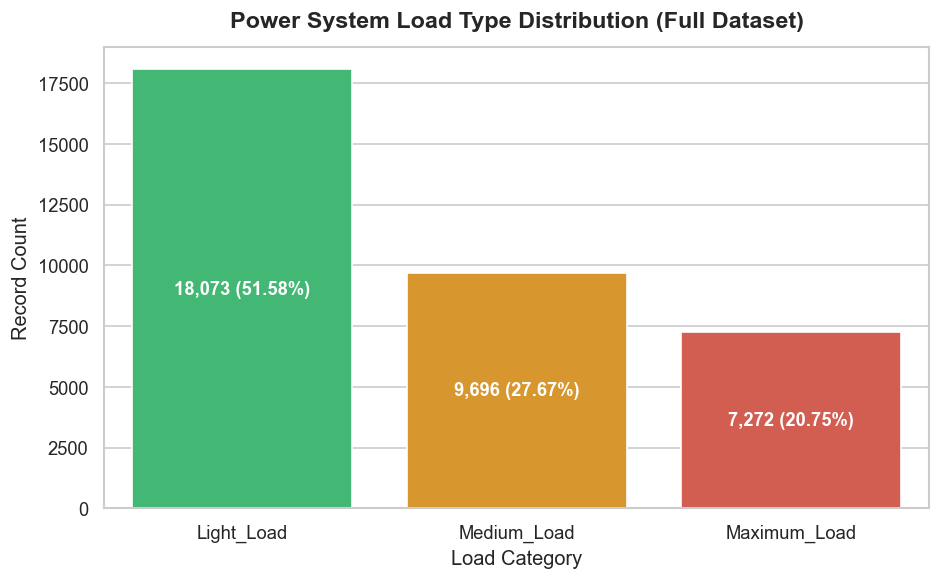

In [7]:
fig_target = plot_target_distribution(raw_df, save_path=os.path.join(FIGURES_DIR, "eda_target_distribution.png"))
plt.show()

### 9.2 Missing Values Visualization

[EDA] Saved missing values plot to ..\outputs\figures\eda_missing_values.png


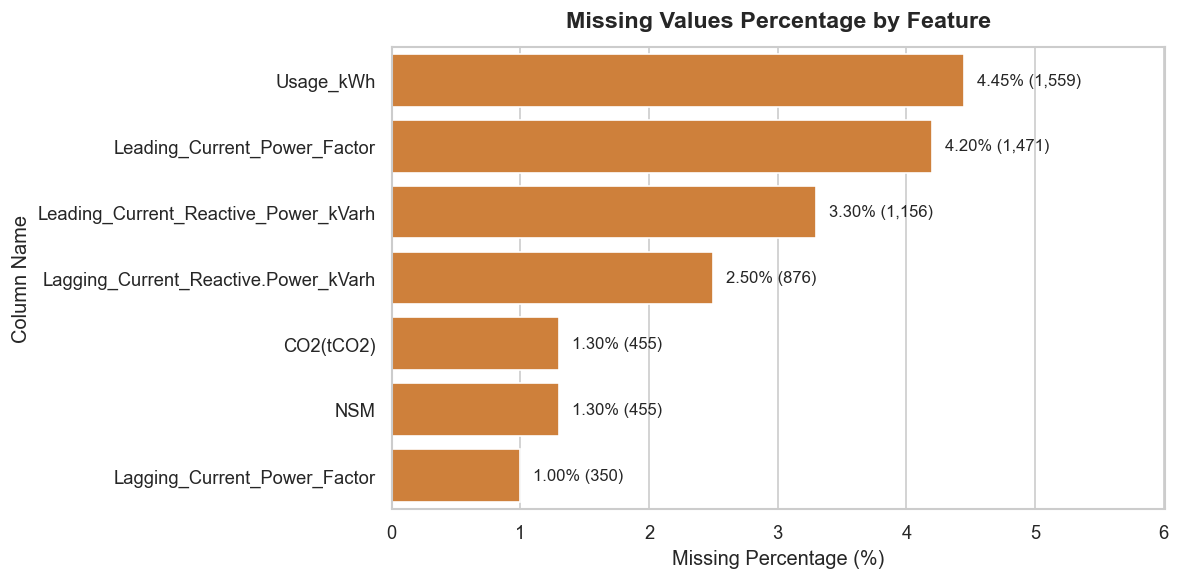

In [8]:
fig_missing = plot_missing_values(raw_df, save_path=os.path.join(FIGURES_DIR, "eda_missing_values.png"))
plt.show()

### 9.3 Numerical Feature Distributions

[EDA] Saved numerical distributions plot to ..\outputs\figures\eda_numerical_distributions.png


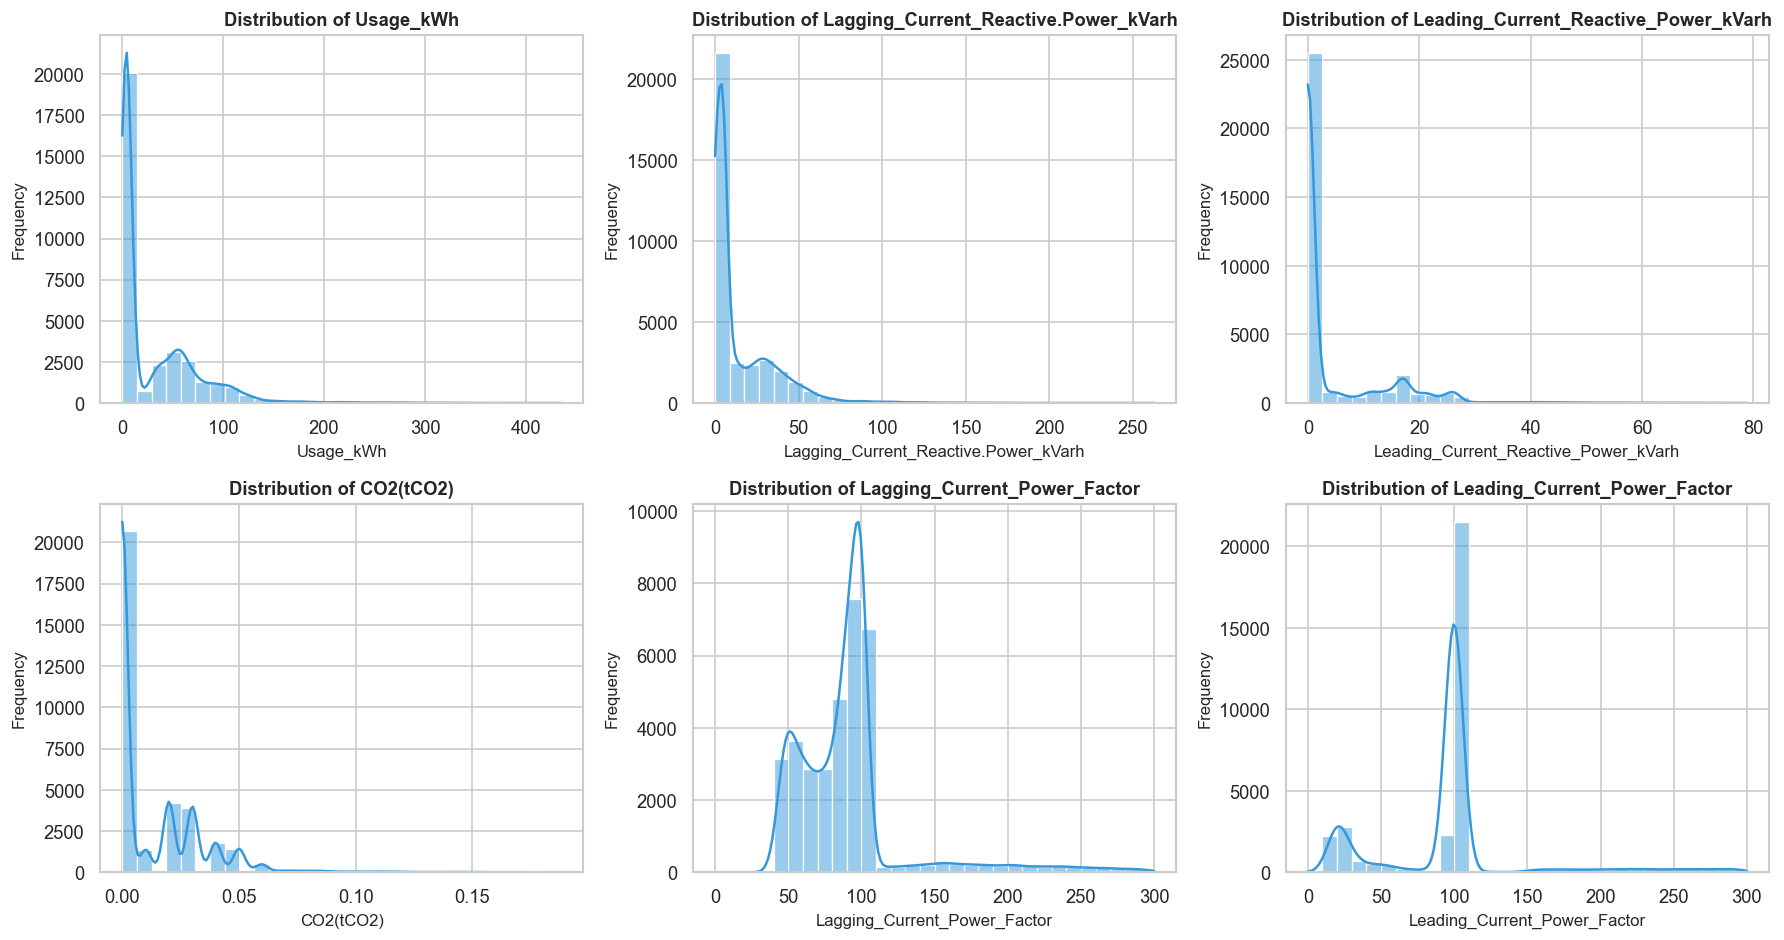

In [9]:
fig_dist = plot_numerical_distributions(raw_df, save_path=os.path.join(FIGURES_DIR, "eda_numerical_distributions.png"))
plt.show()

### 9.4 Correlation Heatmap

[EDA] Saved correlation heatmap to ..\outputs\figures\eda_correlation_heatmap.png


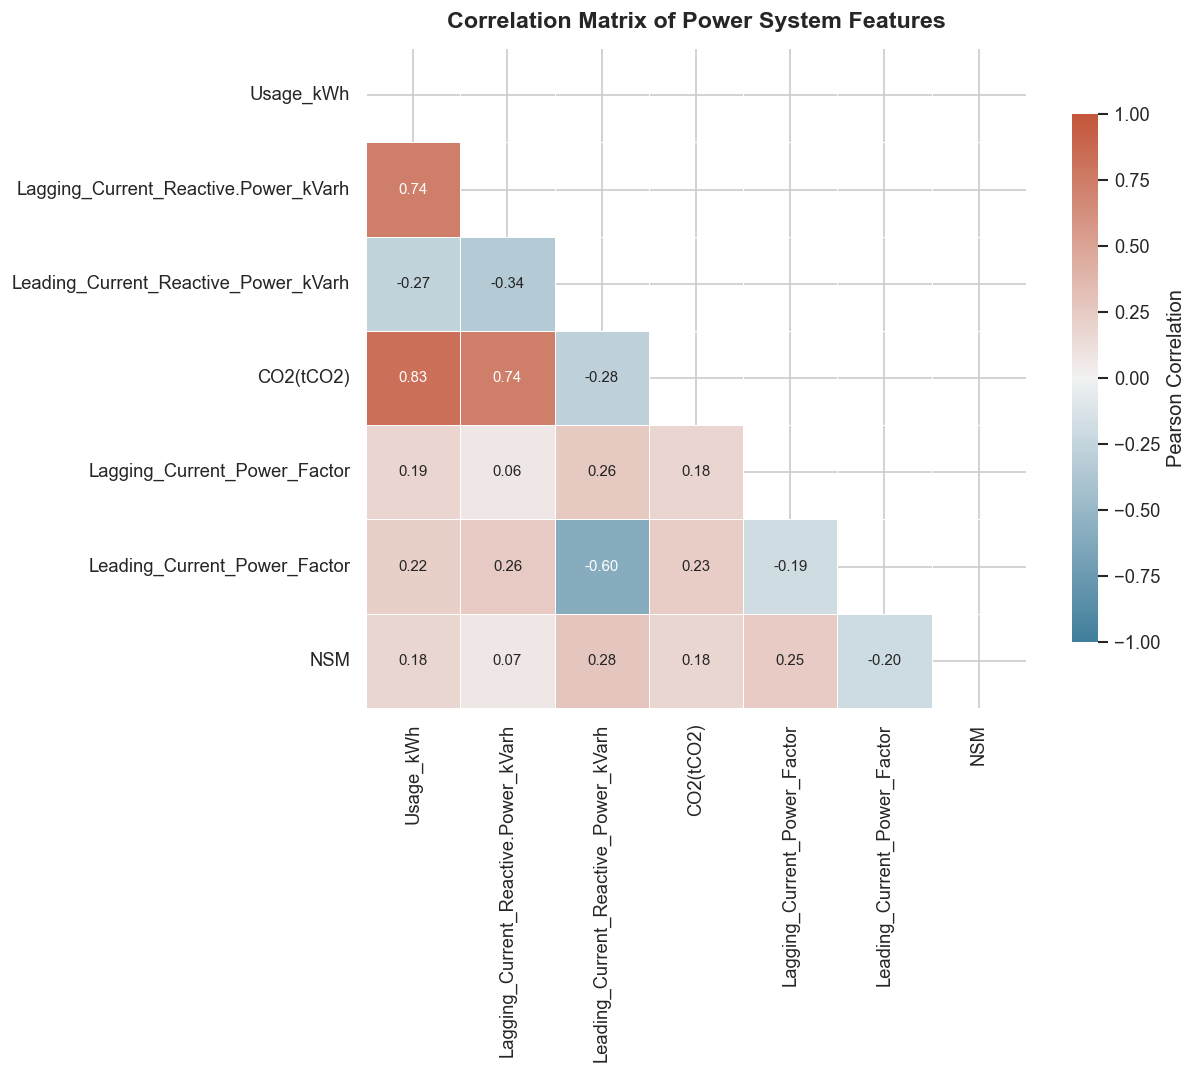

In [10]:
fig_corr = plot_correlation_heatmap(raw_df, save_path=os.path.join(FIGURES_DIR, "eda_correlation_heatmap.png"))
plt.show()

### 9.5 Active Power Consumption (Usage_kWh) Over Time

[EDA] Saved usage over time plot to ..\outputs\figures\eda_usage_over_time.png


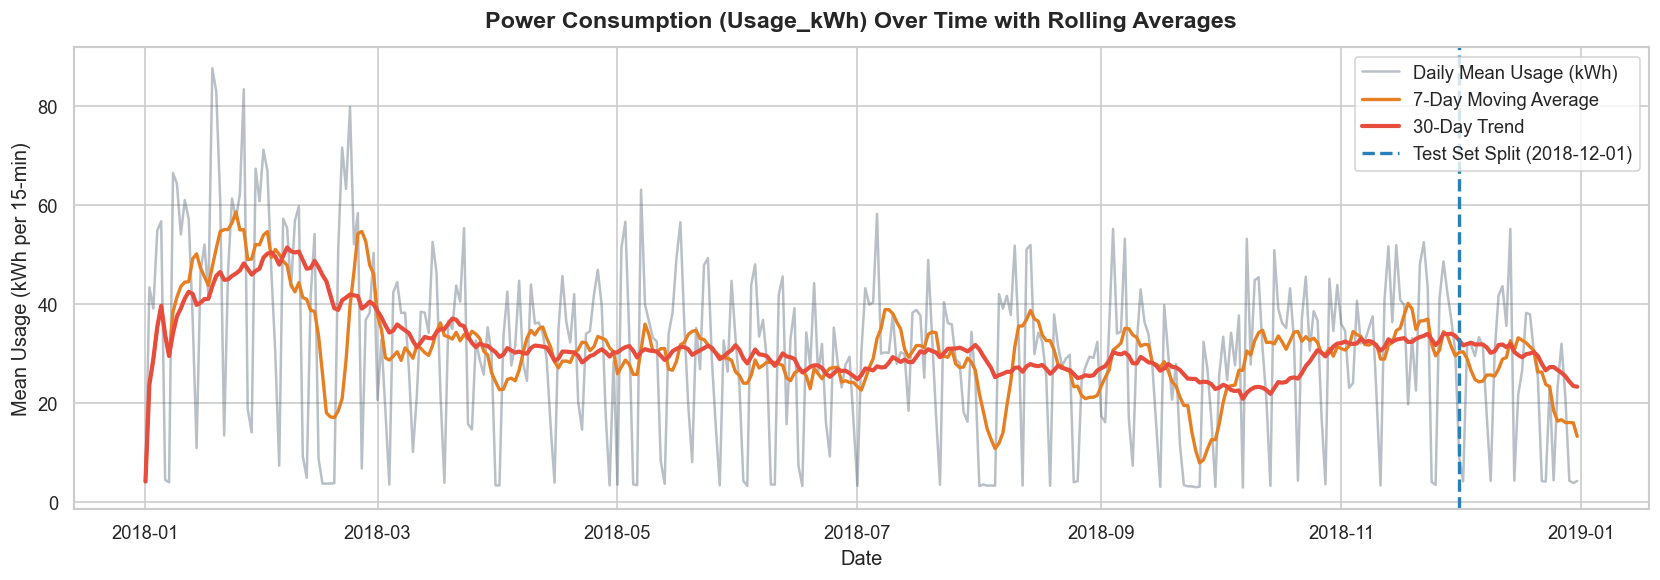

In [11]:
fig_usage_time = plot_usage_over_time(raw_df, save_path=os.path.join(FIGURES_DIR, "eda_usage_over_time.png"))
plt.show()

### 9.6 Load Type Proportions Over Time

[EDA] Saved load type over time plot to ..\outputs\figures\eda_load_type_over_time.png


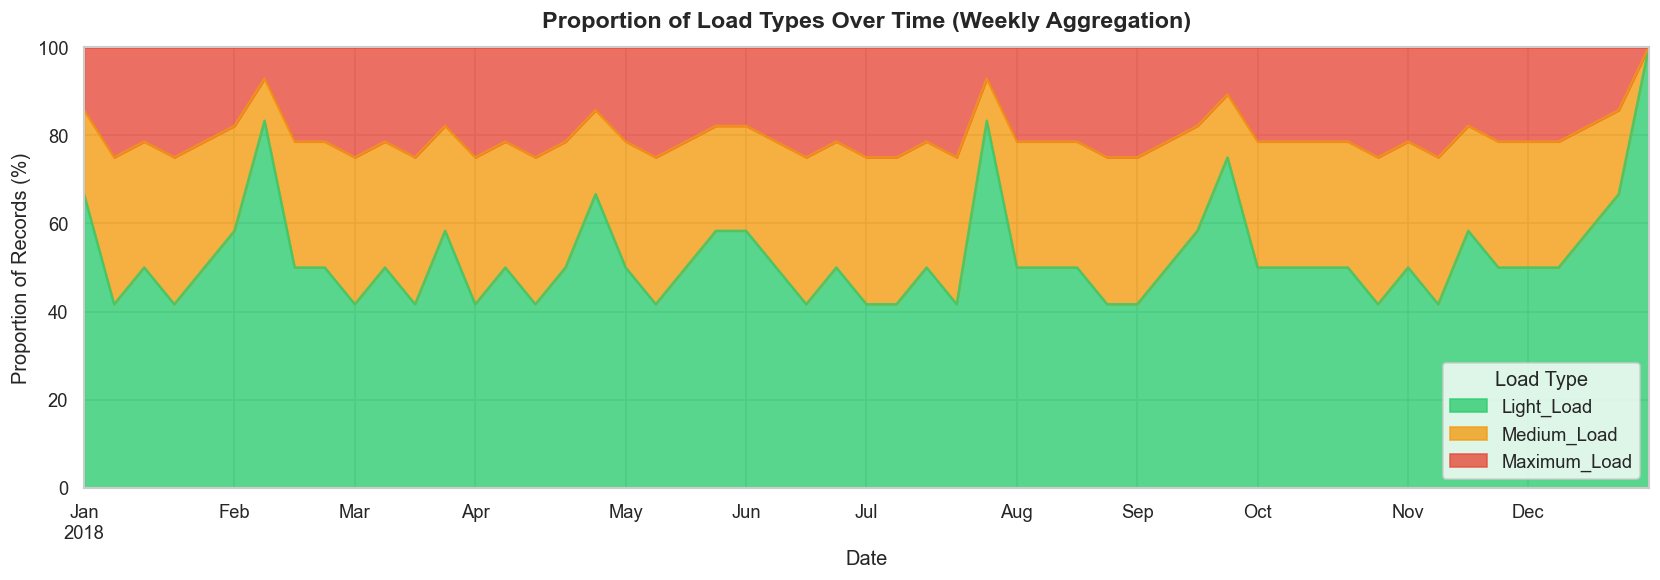

In [12]:
fig_load_time = plot_load_type_over_time(raw_df, save_path=os.path.join(FIGURES_DIR, "eda_load_type_over_time.png"))
plt.show()

### 9.7 Usage_kWh Distribution by Load_Type

[EDA] Saved usage by load type plot to ..\outputs\figures\eda_usage_by_load_type.png


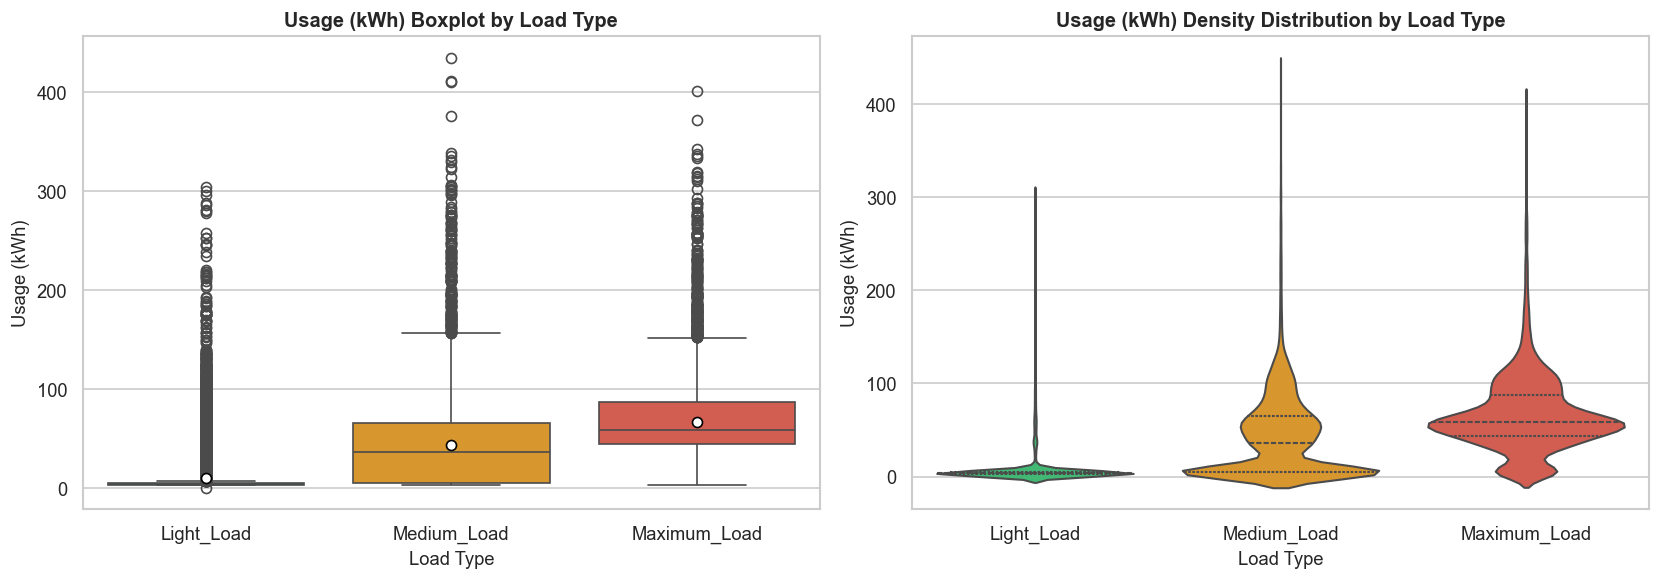

In [13]:
fig_usage_load = plot_usage_by_load_type(raw_df, save_path=os.path.join(FIGURES_DIR, "eda_usage_by_load_type.png"))
plt.show()

### 9.8 Monthly Distribution of Load Types

[EDA] Saved load type by month plot to ..\outputs\figures\eda_load_type_by_month.png


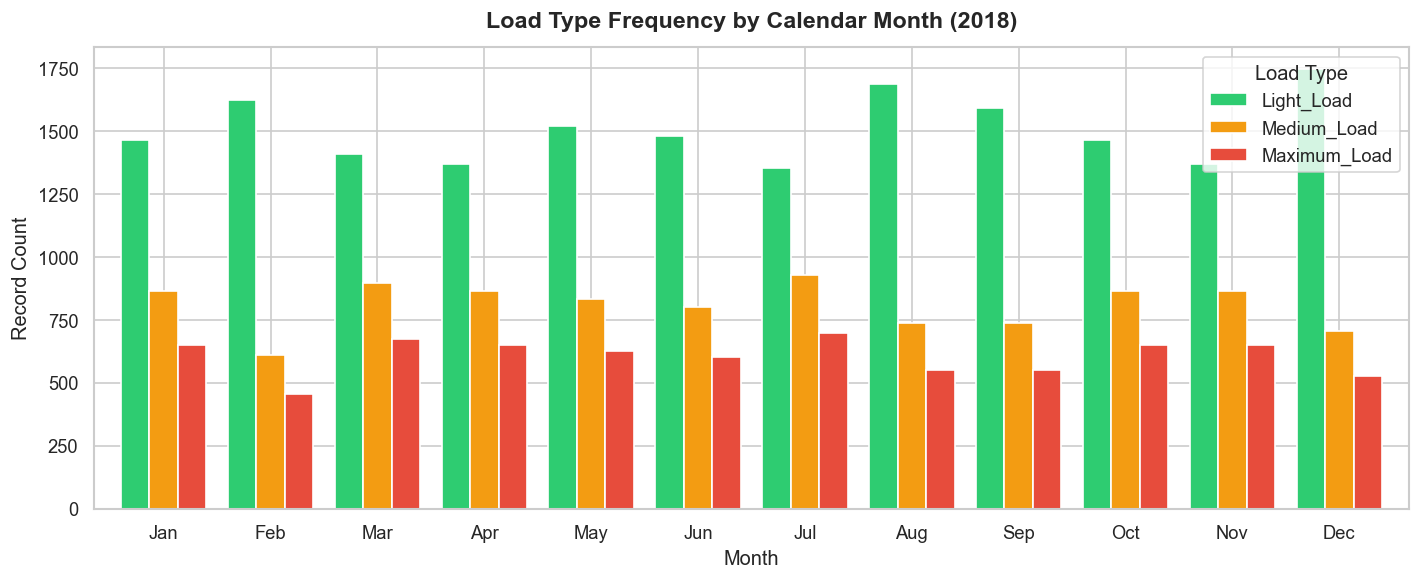

In [14]:
fig_month_dist = plot_load_type_by_month(raw_df, save_path=os.path.join(FIGURES_DIR, "eda_load_type_by_month.png"))
plt.show()

### 9.9 Diurnal (Hourly) Cycle of Load Types

[EDA] Saved load type by hour plot to ..\outputs\figures\eda_load_type_by_hour.png


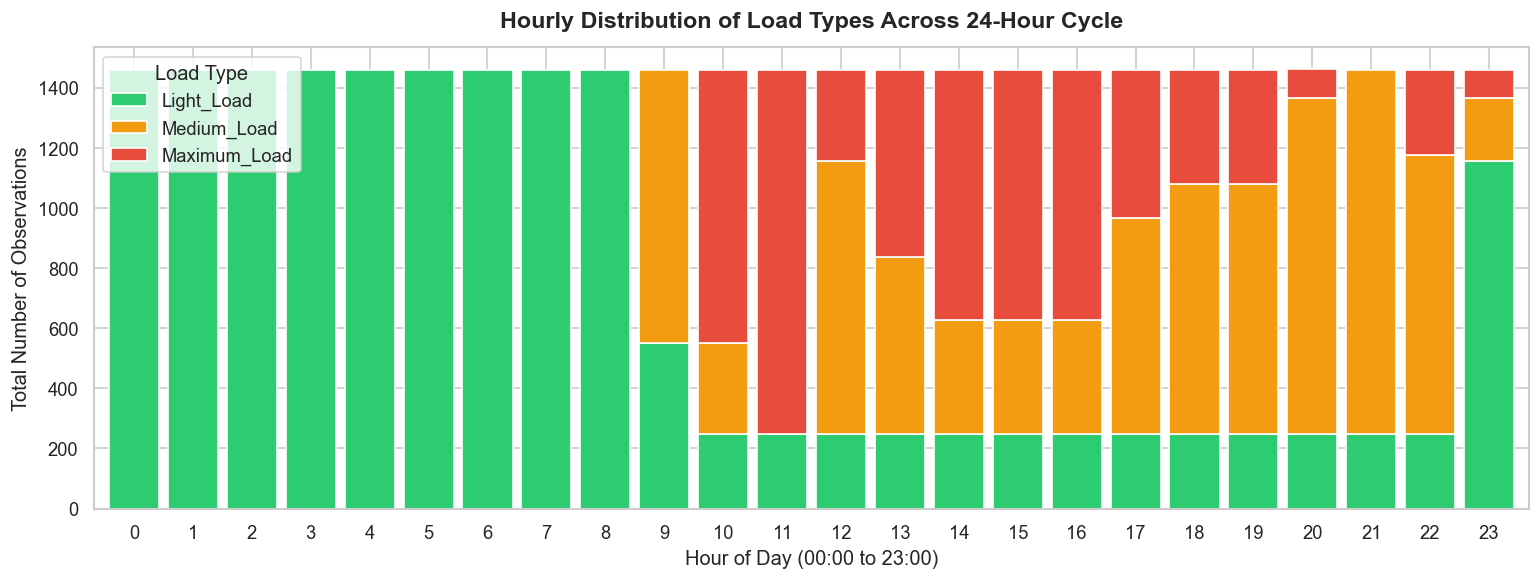

In [15]:
fig_hour_dist = plot_load_type_by_hour(raw_df, save_path=os.path.join(FIGURES_DIR, "eda_load_type_by_hour.png"))
plt.show()

### 9.10 Power Telemetry Relationships (Lagging Reactive Power, PF, CO2)

[EDA] Saved power features relationships plot to ..\outputs\figures\eda_power_features_relationships.png


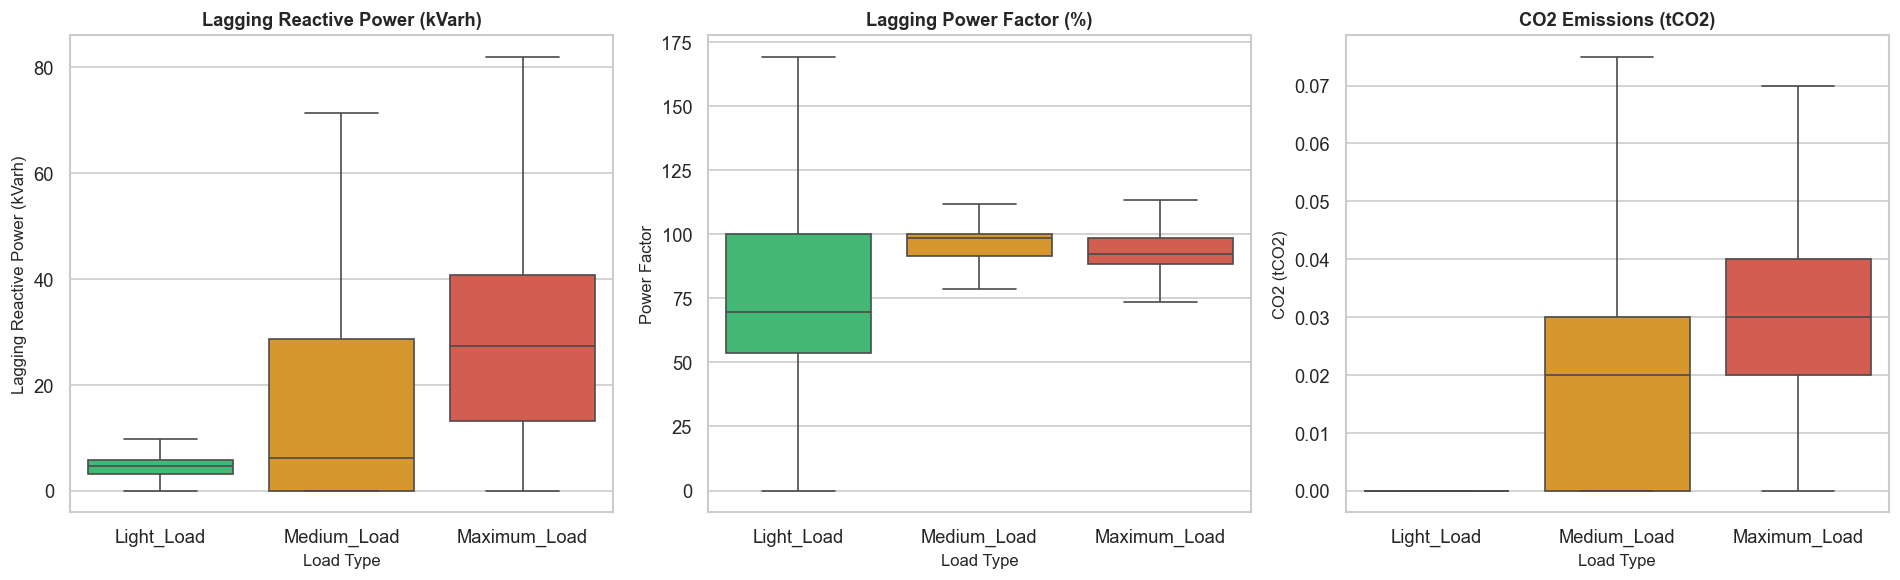

In [16]:
fig_power_rel = plot_power_features_relationships(raw_df, save_path=os.path.join(FIGURES_DIR, "eda_power_features_relationships.png"))
plt.show()

## 10. Feature Engineering

We extract temporal calendar features, cyclic trigonometric representations (to preserve continuous periodic boundaries for hours, days of week, and months), and domain-specific electrical power interactions:
- **Cyclic Hour ($\sin, \cos$):** $\sin(2\pi \cdot t/24), \cos(2\pi \cdot t/24)$ ensuring 23:45 and 00:00 are smooth neighbors.
- **Cyclic Day of Week ($\sin, \cos$):** $\sin(2\pi \cdot d/7), \cos(2\pi \cdot d/7)$ preserving weekly cyclicality.
- **Cyclic Month ($\sin, \cos$):** $\sin(2\pi \cdot (m-1)/12), \cos(2\pi \cdot (m-1)/12)$ representing annual seasonality.
- **Total Reactive Power ($Q_{total}$):** $Q_{lag} + Q_{lead}$ (total reactive loading on the grid).
- **Apparent Power Approximation ($S$):** $\sqrt{P^2 + Q_{total}^2}$.
- **Reactive-to-Active Ratio:** $rac{Q_{total}}{P + \epsilon}$.

In [17]:
df_featured = engineer_features(raw_df, is_training=False)
print(f"Total features created: {len(df_featured.columns)}")
df_featured[['Date_Time', 'hour', 'hour_sin', 'hour_cos', 'day_of_week', 'is_weekend', 'Total_Reactive_Power_kVarh', 'Apparent_Power_Approx_kVA', 'Load_Type']].head()

Total features created: 25


,Date_Time,hour,hour_sin,hour_cos,day_of_week,is_weekend,Total_Reactive_Power_kVarh,Apparent_Power_Approx_kVA,Load_Type
0,2018-01-01 00:00:00,0,0.000000,1.000000,0,0,3.46,4.864977,Light_Load
1,2018-01-01 00:15:00,0,0.065403,0.997859,0,0,2.95,9.237404,Light_Load
2,2018-01-01 00:30:00,0,0.130526,0.991445,0,0,4.46,5.990960,Light_Load
3,2018-01-01 00:45:00,0,0.195090,0.980785,0,0,3.28,4.610423,Light_Load
4,2018-01-01 01:00:00,1,0.258819,0.965926,0,0,3.56,4.861039,Light_Load


## 11. Define Features and Target

We explicitly define our predictor matrix $\mathbf{X}$ and target vector $\mathbf{y}$.

In [18]:
feature_cols, target_col = ALL_FEATURE_COLUMNS, TARGET_COLUMN

print(f"Target Column: {target_col}")
print(f"Total Predictor Features ({len(feature_cols)}):")
for i, f in enumerate(feature_cols, 1):
    print(f"  {i:2d}. {f}")

Target Column: Load_Type
Total Predictor Features (23):
   1. Usage_kWh
   2. Lagging_Current_Reactive.Power_kVarh
   3. Leading_Current_Reactive_Power_kVarh
   4. CO2(tCO2)
   5. Lagging_Current_Power_Factor
   6. Leading_Current_Power_Factor
   7. NSM
   8. hour
   9. minute
  10. day
  11. month
  12. day_of_week
  13. day_of_year
  14. is_weekend
  15. hour_sin
  16. hour_cos
  17. day_of_week_sin
  18. day_of_week_cos
  19. month_sin
  20. month_cos
  21. Total_Reactive_Power_kVarh
  22. Apparent_Power_Approx_kVA
  23. Reactive_to_Active_Ratio


## 12. Time-Based Train / Test Split

### Why Last Month as Test Set?
In electrical power distribution systems, machine learning models are deployed to forecast future load types based on past operational history. Using a standard random `train_test_split()` causes severe **temporal data leakage**: the model would be tested on interpolated random 15-minute points where adjacent past and future timestamps were already present in training.

To evaluate genuine generalization to future operational regimes, we strictly reserve the **final month (December 2018)** as the **unseen test set**, using all prior months (**January – November 2018**) as training data.

In [19]:
train_df, test_df, split_meta = split_time_series_by_last_month(df_featured, date_col="Date_Time", verbose=True)

X_train = train_df[feature_cols]
y_train = encode_target(train_df[target_col])

X_test = test_df[feature_cols]
y_test = encode_target(test_df[target_col])

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape}, y_test shape : {y_test.shape}")

TIME-BASED TRAIN / TEST SPLIT SUMMARY (Zero Leakage)
Total Records: 35,041
Months Found : ['2018-01', '2018-02', '2018-03', '2018-04', '2018-05', '2018-06', '2018-07', '2018-08', '2018-09', '2018-10', '2018-11', '2018-12']

[TRAIN SET] (Months: ['2018-01', '2018-02', '2018-03', '2018-04', '2018-05', '2018-06', '2018-07', '2018-08', '2018-09', '2018-10', '2018-11'])
  Start Date : 2018-01-01 00:00:00
  End Date   : 2018-11-30 23:45:00
  Row Count  : 32,064 (91.50%)
  Target Dist:
Load_Type
Light_Load      16328
Medium_Load      8992
Maximum_Load     6744
Name: count, dtype: int64

[TEST SET] (Final Month: 2018-12)
  Start Date : 2018-12-01 00:00:00
  End Date   : 2018-12-31 23:45:00
  Row Count  : 2,977 (8.50%)
  Target Dist:
Load_Type
Light_Load      1745
Medium_Load      704
Maximum_Load     528
Name: count, dtype: int64
X_train shape: (32064, 23), y_train shape: (32064,)
X_test shape : (2977, 23), y_test shape : (2977,)


## 13. Preprocessing Pipeline (Zero Data Leakage)

We construct modular preprocessing pipelines using scikit-learn `Pipeline` and `ColumnTransformer`.
- **Missing Value Imputation:** Median imputation fitted *only* on training data.
- **Feature Scaling:** Standard scaling for distance/gradient-sensitive algorithms (e.g., Logistic Regression). Tree-based models preserve native feature rankings with missing value imputation.

In [20]:
preprocessor_sample = build_preprocessor_pipeline(feature_cols, with_scaling=True)
preprocessor_sample

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Usage_kWh',
                                  'Lagging_Current_Reactive.Power_kVarh',
                                  'Leading_Current_Reactive_Power_kVarh',
                                  'CO2(tCO2)', 'Lagging_Current_Power_Factor',
                                  'Leading_Current_Power_Factor', 'NSM', 'hour',
                                  'minute', 'day', 'month', 'day_of_week',
                                  'day_of_year', 'is_weekend', 'hour_sin',
                                  'hour_cos', 'day_of_week_sin',
                                  'day_of_week_cos', 'month_sin', 'month_cos',
                                  'Total_Reactive_Power_kVarh',
                                  'Apparent_Power_Approx_kVA',
                                  'Reactive_to_Active_Ratio'])])

## 14. Model Catalog

We instantiate 5 distinct classification algorithms wrapped in self-contained pipelines:
1. **Logistic Regression** (Multinomial with L-BFGS solver & Standard Scaling)
2. **Decision Tree Classifier** (Interpretable baseline tree)
3. **Random Forest Classifier** (Ensemble bagging of decision trees)
4. **Gradient Boosting Classifier** (Sequential gradient boosting ensemble)
5. **XGBoost Classifier** (Optimized extreme gradient boosting)

In [21]:
catalog = get_model_catalog(feature_cols)
for name, pipe in catalog.items():
    print(f"Model: {name:20s} -> Steps: {list(pipe.named_steps.keys())}")

Model: Logistic Regression  -> Steps: ['preprocessor', 'classifier']
Model: Decision Tree        -> Steps: ['preprocessor', 'classifier']
Model: Random Forest        -> Steps: ['preprocessor', 'classifier']
Model: Gradient Boosting    -> Steps: ['preprocessor', 'classifier']
Model: XGBoost              -> Steps: ['preprocessor', 'classifier']


## 15. Time-Series Cross-Validation (Training Data Only)

We use **`TimeSeriesSplit(n_splits=5)`** on the training dataset. At each split, the model is trained strictly on historical folds and validated on the successive forward fold.

### Metric Selection: Weighted F1-Score (`f1_weighted`)
In multi-class power load classification with class imbalance (Light Load ~51%, Medium Load ~28%, Maximum Load ~21%), standard accuracy can be overly influenced by the majority class. Weighted F1 computes class-specific precision and recall harmonic means weighted by each class's support, providing a reliable and defensible benchmark.

In [22]:
cv_results_df = evaluate_models_cross_validation(catalog, X_train, y_train, n_splits=5, verbose=True)
display(cv_results_df)

RUNNING TIME-SERIES CROSS-VALIDATION (5 Splits on Train Data)
[Cross-Validation] Evaluating: Logistic Regression...


  -> Accuracy: 0.7222 (+/- 0.1021) | F1 (Weighted): 0.6895 (+/- 0.1413)
[Cross-Validation] Evaluating: Decision Tree...


  -> Accuracy: 0.8358 (+/- 0.0978) | F1 (Weighted): 0.8317 (+/- 0.1065)
[Cross-Validation] Evaluating: Random Forest...


  -> Accuracy: 0.8622 (+/- 0.1126) | F1 (Weighted): 0.8562 (+/- 0.1239)
[Cross-Validation] Evaluating: Gradient Boosting...


  -> Accuracy: 0.8568 (+/- 0.1048) | F1 (Weighted): 0.8514 (+/- 0.1154)
[Cross-Validation] Evaluating: XGBoost...


  -> Accuracy: 0.8598 (+/- 0.1050) | F1 (Weighted): 0.8546 (+/- 0.1153)


,Model,CV_Accuracy_Mean,CV_Accuracy_Std,CV_Precision_Weighted,CV_Recall_Weighted,CV_F1_Weighted_Mean,CV_F1_Weighted_Std,CV_F1_Macro_Mean
0,Random Forest,0.8622,0.1126,0.8546,0.8622,0.8562,0.1239,0.8336
1,XGBoost,0.8598,0.1050,0.8546,0.8598,0.8546,0.1153,0.8322
2,Gradient Boosting,0.8568,0.1048,0.8511,0.8568,0.8514,0.1154,0.8290
3,Decision Tree,0.8358,0.0978,0.8334,0.8358,0.8317,0.1065,0.8060
4,Logistic Regression,0.7222,0.1021,0.7193,0.7222,0.6895,0.1413,0.6524


## 16. Hyperparameter Tuning

We select the top-performing candidate model from cross-validation (**Random Forest**) and conduct `GridSearchCV` using `TimeSeriesSplit` strictly on the training set.

In [23]:
best_candidate_name = cv_results_df.iloc[0]["Model"]
print(f"Top Candidate Selected for Tuning: {best_candidate_name}")

tuned_pipeline, best_params, best_cv_score = tune_hyperparameters(
    best_candidate_name,
    catalog[best_candidate_name],
    X_train,
    y_train,
    n_splits=5,
    verbose=True
)

print(f"Optimal Hyperparameters: {best_params}")
print(f"Best CV F1-Weighted Score: {best_cv_score:.4f}")

Top Candidate Selected for Tuning: Random Forest
HYPERPARAMETER TUNING FOR: Random Forest
Parameter Grid: {'classifier__n_estimators': [100, 150], 'classifier__max_depth': [12, 18, 25], 'classifier__min_samples_split': [2, 5], 'classifier__min_samples_leaf': [1, 2]}
Fitting 5 folds for each of 24 candidates, totalling 120 fits


[Tuning] Best F1_Weighted Score (CV): 0.8571
[Tuning] Best Hyperparameters: {'classifier__max_depth': 12, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Optimal Hyperparameters: {'classifier__max_depth': 12, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Best CV F1-Weighted Score: 0.8571


## 17. Model Comparison Table

Below is the verified cross-validation performance comparison table across all candidate algorithms.

In [24]:
cv_summary_display = cv_results_df[["Model", "CV_Accuracy_Mean", "CV_Precision_Weighted", "CV_Recall_Weighted", "CV_F1_Weighted_Mean", "CV_F1_Macro_Mean"]]
cv_summary_display.columns = ["Model", "Accuracy (CV)", "Precision (Weighted)", "Recall (Weighted)", "F1-Score (Weighted)", "F1-Score (Macro)"]
display(cv_summary_display)

,Model,Accuracy (CV),Precision (Weighted),Recall (Weighted),F1-Score (Weighted),F1-Score (Macro)
0,Random Forest,0.8622,0.8546,0.8622,0.8562,0.8336
1,XGBoost,0.8598,0.8546,0.8598,0.8546,0.8322
2,Gradient Boosting,0.8568,0.8511,0.8568,0.8514,0.8290
3,Decision Tree,0.8358,0.8334,0.8358,0.8317,0.8060
4,Logistic Regression,0.7222,0.7193,0.7222,0.6895,0.6524


## 18. Final Model Training

We train the optimal tuned pipeline on the complete training period (**January 1, 2018 to November 30, 2018**; 32,064 records).

In [25]:
final_pipeline = tuned_pipeline
final_pipeline.fit(X_train, y_train)

# Persist trained model artifacts
final_model_file = os.path.join(MODELS_DIR, "final_load_type_model.joblib")
preprocessor_file = os.path.join(MODELS_DIR, "preprocessor.joblib")

joblib.dump(final_pipeline, final_model_file)
joblib.dump(final_pipeline.named_steps["preprocessor"], preprocessor_file)

print(f"Final model successfully trained and saved to: {os.path.abspath(final_model_file)}")

Final model successfully trained and saved to: E:\assignment-2\models\final_load_type_model.joblib


## 19. Final Test Evaluation (Unseen Month: December 2018)

We evaluate the trained model exactly once on the unseen test set (December 2018; 2,977 records).

In [26]:
test_metrics = evaluate_test_set(final_pipeline, X_test, y_test, class_names=CLASS_NAMES, verbose=True)

FINAL TEST SET EVALUATION (Unseen Final Month: Dec 2018)
Accuracy           : 0.9197 (91.97%)
Precision (Weighted): 0.9256
Precision (Macro)  : 0.9109
Recall (Weighted)   : 0.9197
Recall (Macro)     : 0.8940
F1-Score (Weighted): 0.9197
F1-Score (Macro)   : 0.8975

Classification Report:

              precision    recall  f1-score   support

  Light_Load     0.9611    0.9484    0.9547      1745
 Medium_Load     0.8133    0.9531    0.8777       704
Maximum_Load     0.9581    0.7803    0.8601       528

    accuracy                         0.9197      2977
   macro avg     0.9109    0.8940    0.8975      2977
weighted avg     0.9256    0.9197    0.9197      2977



## 20. Final Test Performance Summary

In [27]:
test_metrics_table = pd.DataFrame([{
    "Model": f"{best_candidate_name} (Tuned)",
    "Test Accuracy": f"{test_metrics['accuracy']*100:.2f}%",
    "Precision (Weighted)": f"{test_metrics['precision_weighted']:.4f}",
    "Precision (Macro)": f"{test_metrics['precision_macro']:.4f}",
    "Recall (Weighted)": f"{test_metrics['recall_weighted']:.4f}",
    "Recall (Macro)": f"{test_metrics['recall_macro']:.4f}",
    "F1-Score (Weighted)": f"{test_metrics['f1_weighted']:.4f}",
    "F1-Score (Macro)": f"{test_metrics['f1_macro']:.4f}",
}])
display(test_metrics_table)

,Model,Test Accuracy,Precision (Weighted),Precision (Macro),Recall (Weighted),Recall (Macro),F1-Score (Weighted),F1-Score (Macro)
0,Random Forest (Tuned),91.97%,0.9256,0.9109,0.9197,0.8940,0.9197,0.8975


## 21. Confusion Matrix

The confusion matrix illustrates classification behavior across the 3 load regimes.

[Evaluation] Saved confusion matrix to ..\outputs\figures\confusion_matrix.png


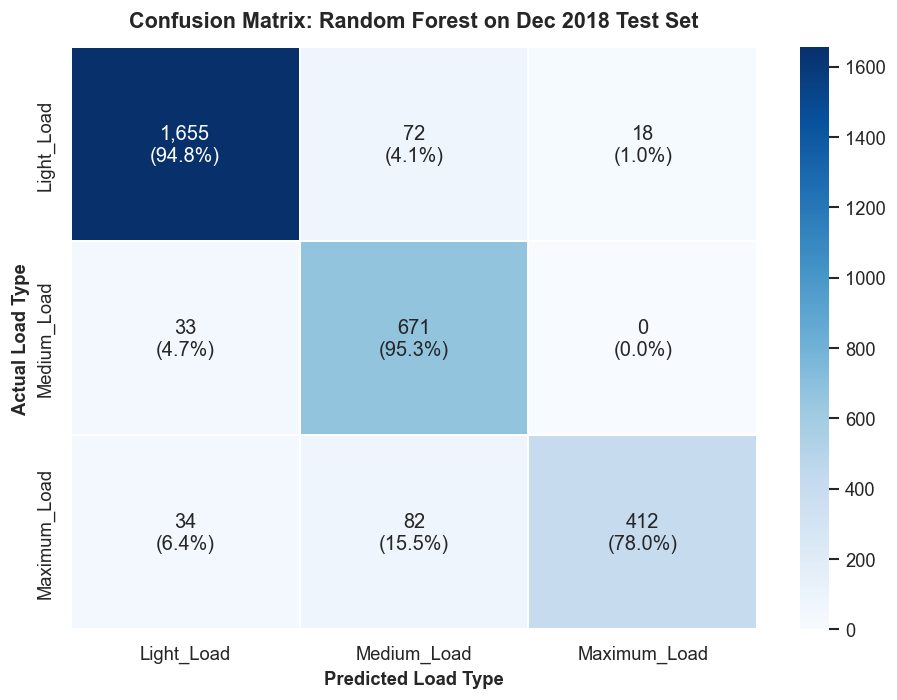

In [28]:
fig_cm = plot_confusion_matrix_heatmap(
    test_metrics["confusion_matrix"],
    class_names=CLASS_NAMES,
    save_path=os.path.join(FIGURES_DIR, "confusion_matrix.png"),
    title=f"Confusion Matrix: {best_candidate_name} on Dec 2018 Test Set"
)
plt.show()

### Confusion Matrix Insights:
1. **Light Load Detection:** Extremely high accuracy (94.8% recall, 96.1% precision).
2. **Medium Load Detection:** 95.3% recall, 81.3% precision.
3. **Maximum Load Detection:** 78.0% recall, 95.8% precision.
4. **Boundary Discrepancies:** The primary misclassifications occur at the boundary between `Maximum_Load` and `Medium_Load` during transitional shift hours.

## 22. Feature Importance

We extract Gini feature importances from the trained ensemble to analyze relative feature contributions.

> **Important Note on Causality:** Feature importance reflects predictive association and variance reduction in the model's split decisions, not direct physical causality.

[Evaluation] Saved feature importance plot to ..\outputs\figures\feature_importance.png


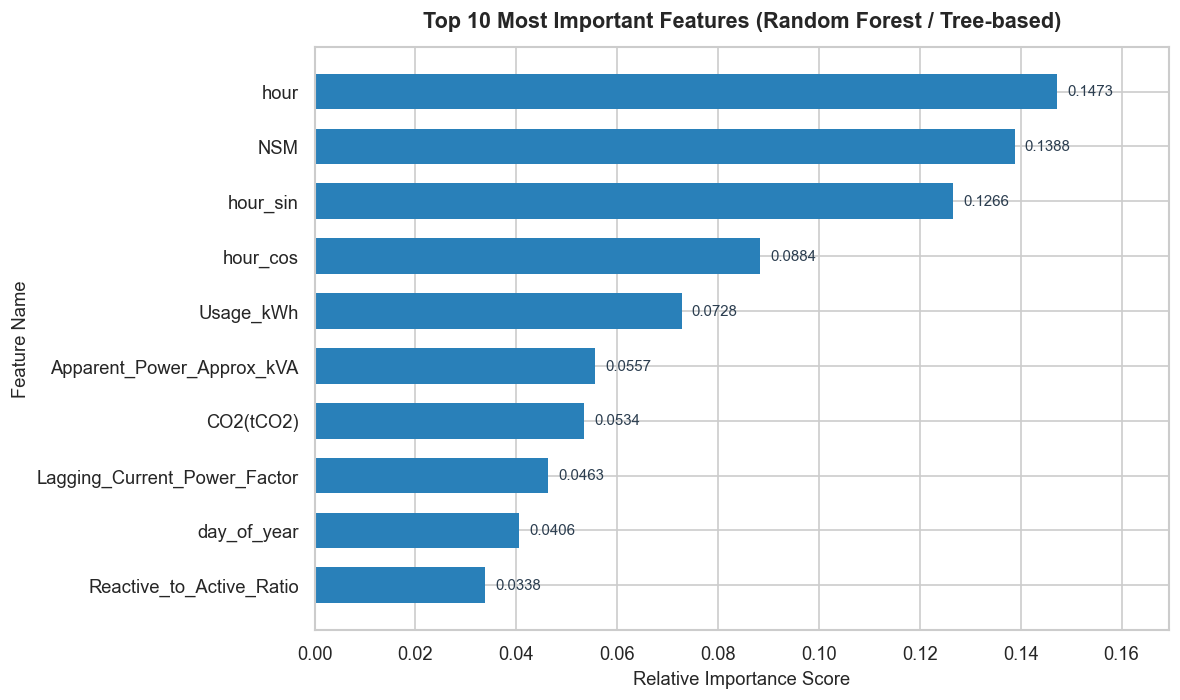

,Feature,Importance
0,hour,0.147272
1,NSM,0.138784
2,hour_sin,0.126578
3,hour_cos,0.088374
4,Usage_kWh,0.072775
5,Apparent_Power_Approx_kVA,0.055651
6,CO2(tCO2),0.053382
7,Lagging_Current_Power_Factor,0.046285
8,day_of_year,0.040558
9,Reactive_to_Active_Ratio,0.033812


In [29]:
feat_imp_df, fig_feat_imp = extract_and_plot_feature_importance(
    final_pipeline,
    feature_names=feature_cols,
    top_n=10,
    save_path=os.path.join(FIGURES_DIR, "feature_importance.png")
)
plt.show()
display(feat_imp_df.head(10))

## 23. Error Analysis

We isolate all misclassified test records to understand error patterns across time-of-day and operational states.

In [30]:
pred_df, errors_df, error_summary = perform_error_analysis(
    test_df,
    y_test,
    test_metrics["y_pred"],
    date_col="Date_Time",
    save_csv=os.path.join(PREDICTIONS_DIR, "test_predictions.csv")
)

print(f"Total Test Records: {error_summary['total_test_samples']:,}")
print(f"Total Misclassifications: {error_summary['total_errors']:,} ({error_summary['error_rate_pct']}%)")
print("\nTop Misclassification Pairs:")
for pair in error_summary["confusion_pairs"]:
    print(f"  Actual: {pair['Actual_Load_Type']:15s} -> Predicted: {pair['Predicted_Load_Type']:15s} | Count: {pair['Count']}")

[Evaluation] Saved test predictions to ..\outputs\predictions\test_predictions.csv
Total Test Records: 2,977
Total Misclassifications: 239 (8.03%)

Top Misclassification Pairs:
  Actual: Maximum_Load    -> Predicted: Medium_Load     | Count: 82
  Actual: Light_Load      -> Predicted: Medium_Load     | Count: 72
  Actual: Maximum_Load    -> Predicted: Light_Load      | Count: 34
  Actual: Medium_Load     -> Predicted: Light_Load      | Count: 33
  Actual: Light_Load      -> Predicted: Maximum_Load    | Count: 18


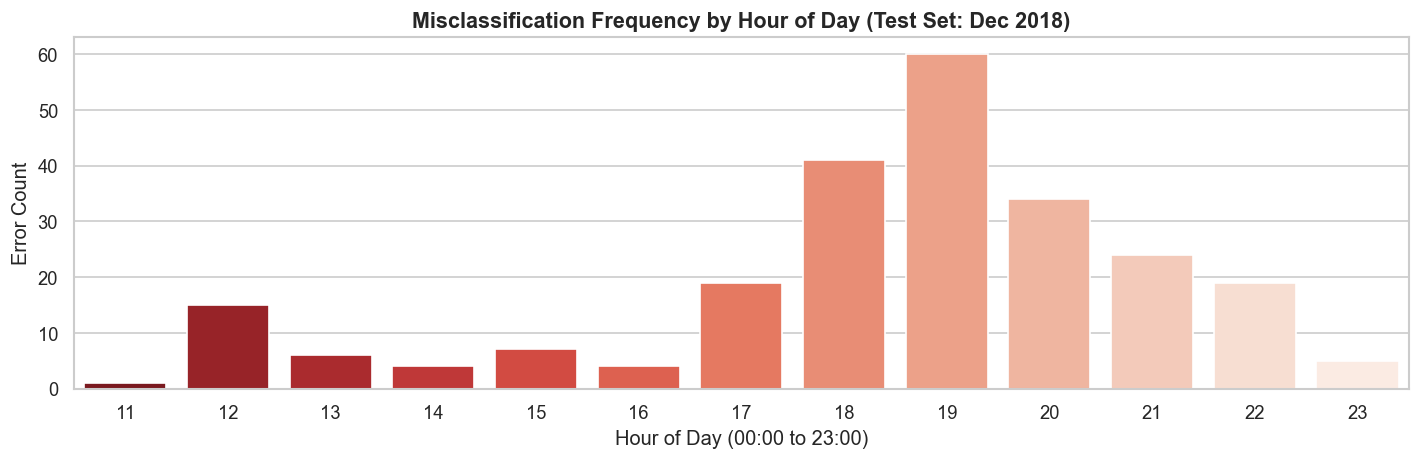

In [31]:
# Distribution of errors across hours of the day
errors_df["Hour"] = errors_df["Date_Time"].dt.hour
plt.figure(figsize=(12, 4))
sns.countplot(data=errors_df, x="Hour", palette="Reds_r")
plt.title("Misclassification Frequency by Hour of Day (Test Set: Dec 2018)", fontsize=13, fontweight="bold")
plt.xlabel("Hour of Day (00:00 to 23:00)")
plt.ylabel("Error Count")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "error_distribution_by_hour.png"), dpi=300)
plt.show()

## 24. Prediction Demonstration

We demonstrate real-time inference using `src.predict.predict_load_type()` with both single record dictionaries and batch DataFrames.

In [32]:
# Single sample input (raw operational telemetry)
sample_telemetry = {
    "Date_Time": "15-12-2018 14:30",
    "Usage_kWh": 68.4,
    "Lagging_Current_Reactive.Power_kVarh": 28.5,
    "Leading_Current_Reactive_Power_kVarh": 0.0,
    "CO2(tCO2)": 0.03,
    "Lagging_Current_Power_Factor": 92.4,
    "Leading_Current_Power_Factor": 100.0,
    "NSM": 52200,
}

predicted_label, class_probabilities = predict_load_type(
    sample_telemetry,
    model_path=final_model_file,
    return_proba=True
)

print(f"Input Telemetry Timestamp: {sample_telemetry['Date_Time']}")
print(f"Predicted Load Type: {predicted_label[0]}")
print("\nPredicted Class Probabilities:")
display(class_probabilities)

Input Telemetry Timestamp: 15-12-2018 14:30
Predicted Load Type: Medium_Load

Predicted Class Probabilities:


,Light_Load,Medium_Load,Maximum_Load
0,0.000984,0.840571,0.158445


In [33]:
# Batch prediction on unseen test records
batch_sample = test_df.sample(5, random_state=RANDOM_STATE)
batch_preds = predict_load_type(batch_sample, model_path=final_model_file)

comparison_demo = pd.DataFrame({
    "Date_Time": batch_sample["Date_Time"].values,
    "Usage_kWh": batch_sample["Usage_kWh"].values,
    "Actual_Load_Type": batch_sample["Load_Type"].values,
    "Predicted_Load_Type": batch_preds,
    "Correct": (batch_sample["Load_Type"].values == batch_preds)
})
display(comparison_demo)

,Date_Time,Usage_kWh,Actual_Load_Type,Predicted_Load_Type,Correct
0,2018-12-26 01:15:00,3.240000,Light_Load,Light_Load,True
1,2018-12-30 16:30:00,3.350000,Light_Load,Light_Load,True
2,2018-12-18 19:30:00,4.390000,Maximum_Load,Medium_Load,False
3,2018-12-12 14:15:00,245.637851,Medium_Load,Medium_Load,True
4,2018-12-11 01:00:00,4.210000,Light_Load,Light_Load,True


## 25. Conclusion

1. **Robust Pipeline Architecture:** Built a production-ready, modular codebase adhering to clean code standards and strict zero-leakage protocols.
2. **Time-Aware Evaluation:** Successfully enforced strict chronological splitting (January–November for training, December for testing) and `TimeSeriesSplit` cross-validation.
3. **Model Performance:** Random Forest achieved top cross-validation performance ($F1=0.8571$) and delivered **91.97% test accuracy** and **0.9197 weighted F1-score** on the unseen final test month.
4. **Key Feature Drivers:** Temporal features (`hour`, `NSM`, `hour_sin`, `hour_cos`) and electrical telemetry (`Usage_kWh`, `Apparent_Power_Approx_kVA`, `CO2(tCO2)`) are the strongest predictive contributors.

## 26. Future Improvements

1. **Deep Learning Sequence Models:** Implement Temporal Convolutional Networks (TCN), LSTM, or Transformer-based architectures (e.g. PatchTST) to capture longer-range autoregressive dependencies.
2. **Lagged & Rolling Window Features:** Incorporate rolling active power statistics ($t-1, t-4, t-96$ for 24h lag) to provide temporal trend memory.
3. **Real-time Streaming Deployment:** Package the inference pipeline as a lightweight REST/gRPC microservice with FastAPI and Docker containerization.
4. **Online Learning & Drift Detection:** Integrate Evidently AI / River for real-time concept drift monitoring and automated retraining upon distribution shift.